# Data Processing

## Import packages
Dependency Specification: pandas==3.0.5, duckdb==1.5.6

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from utils import *

## Load Data

Load data and select features with an SQL query through the duckdb.

Based on the EDA results, `year`, `patch`, and `gamelength` are removed because they have 0.00 correlation with the target variable `result`.
On the other hand, `towers`, `assists`, and `goldspent` are removed because they have high correlation with other variables, which may cause multicollinearity during modeling. 

In [2]:
# Adjust list based on the features considered
cols_to_include = ['gameid', 'league', 'teamname', 'result', 'kills',
                   'deaths', 'dpm', 'damagetakenperminute',
                   'wardskilled', 'totalgold', 'split']

db = 'lol_predictors.duckdb'
df_selected = "df_2014" # temporarily hardcoded df name
df = data_selection(df_selected, cols_to_include, db)

## Data Cleaning

For **data imputation**, only the feature `split` has missing values based on df_2014's EDA. We can use the previous value for each NaN since there's only two values, which are `Summer` and `Spring`, and they are sorted chronologically.

In [3]:
df['split'] = df['split'].ffill()

We will **trim outliers** because even the feature `wardskilled` that has the highest outlier percentage only has `<2%` of outliers.

In [4]:
num_cols = df.select_dtypes(include=["number"]).columns.tolist()

for col in num_cols:
    df = df[~detect_outliers(df, col).to_numpy()]

This concludes data cleaning of df_2014, which is the Lol Esports data on 2014 based on Oracle's Elixir. From the EDA, there are no categories in categorical features that needs fixing. 

## Post-Processing Data Audit

In [5]:
df.info()

<class 'pandas.DataFrame'>
Index: 1748 entries, 0 to 1835
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   gameid                1748 non-null   str    
 1   league                1748 non-null   str    
 2   teamname              1748 non-null   str    
 3   result                1748 non-null   int64  
 4   kills                 1748 non-null   int64  
 5   deaths                1748 non-null   int64  
 6   dpm                   1748 non-null   float64
 7   damagetakenperminute  1748 non-null   float64
 8   wardskilled           1748 non-null   int64  
 9   totalgold             1748 non-null   int64  
 10  split                 1748 non-null   str    
dtypes: float64(2), int64(5), str(4)
memory usage: 163.9 KB


In [6]:
df.shape

(1748, 11)

In [7]:
display(df.describe())

,result,kills,deaths,dpm,damagetakenperminute,wardskilled,totalgold
count,1748.000000,1748.000000,1748.000000,1748.000000,1748.000000,1748.000000,1748.000000
mean,0.496568,13.131579,13.219680,1874.503397,2668.539321,26.433638,60673.950229
std,0.500131,7.140336,7.185005,442.493399,434.566315,12.148040,14639.426478
min,0.000000,0.000000,0.000000,676.410300,1491.435000,2.000000,23991.000000
25%,0.000000,7.000000,7.000000,1560.488100,2365.139850,17.000000,50117.500000
50%,0.000000,13.000000,13.000000,1869.605550,2663.667250,25.000000,60373.500000
75%,1.000000,18.000000,18.000000,2177.424125,2961.576775,34.000000,70638.250000
max,1.000000,34.000000,34.000000,3076.483700,3870.868000,59.000000,100425.000000


In [8]:
data_profiling(df)

List of Columns: Index(['gameid', 'league', 'teamname', 'result', 'kills', 'deaths', 'dpm',
       'damagetakenperminute', 'wardskilled', 'totalgold', 'split'],
      dtype='str')

------------ COUNT OF MISSING VALUES -------------


gameid                  0
league                  0
teamname                0
result                  0
kills                   0
deaths                  0
dpm                     0
damagetakenperminute    0
wardskilled             0
totalgold               0
split                   0
dtype: int64


------------- COUNT OF UNIQUE VALUES -------------


gameid                   887
league                     5
teamname                  80
result                     2
kills                     35
deaths                    35
dpm                     1748
damagetakenperminute    1747
wardskilled               58
totalgold               1721
split                      2
dtype: int64


--------- UNIQUE VALUES OF OBJECT SERIES ---------

 league
NA LCS    642
EU LCS    622
NA CS     171
EU CS     168
WLDs      145
Name: count, dtype: int64

 teamname
TSM                      82
Alliance                 77
Cloud9                   77
Fnatic                   74
SK Gaming                74
Counter Logic Gaming     74
Team Curse               72
Team ROCCAT              71
Team Coast               71
Dignitas                 68
Copenhagen Wolves        67
Millenium                67
Evil Geniuses            62
LMQ                      62
Gambit Gaming            61
SUPA HOT CREW            58
Curse Academy            43
Ninjas in Pyjamas        35
Reason Gaming            35
XDG Gaming               32
compLexity Gaming        29
H2k-Gaming               29
SK Gaming Prime          27
Team LoLPro              24
Team 8                   22
Gamers2                  20
Royal Club               19
compLexity.Black         18
Unicorns of Love         16
Samsung White       

In [9]:
# Define numerical columns
num_cols = df.select_dtypes(include=["number"]).columns.drop(['result']).tolist()

# Define categorical columns
cat_cols = df.select_dtypes(include=["str"]).columns.drop(['gameid']).tolist()

In [10]:
count_outliers(df, num_cols)


--------------- COUNT OF OUTLIERS ----------------
kills:                      0 (0.00%)
deaths:                     0 (0.00%)
dpm:                        0 (0.00%)
damagetakenperminute:       3 (0.17%)
wardskilled:                0 (0.00%)
totalgold:                  0 (0.00%)


*Note that the IQR bounds are dynamically recalculated on each call. These remaining outliers are relative to the newly trimmed distribution. Since the new percentage of outliers is < 1%, it is negligible and safe to retain.*

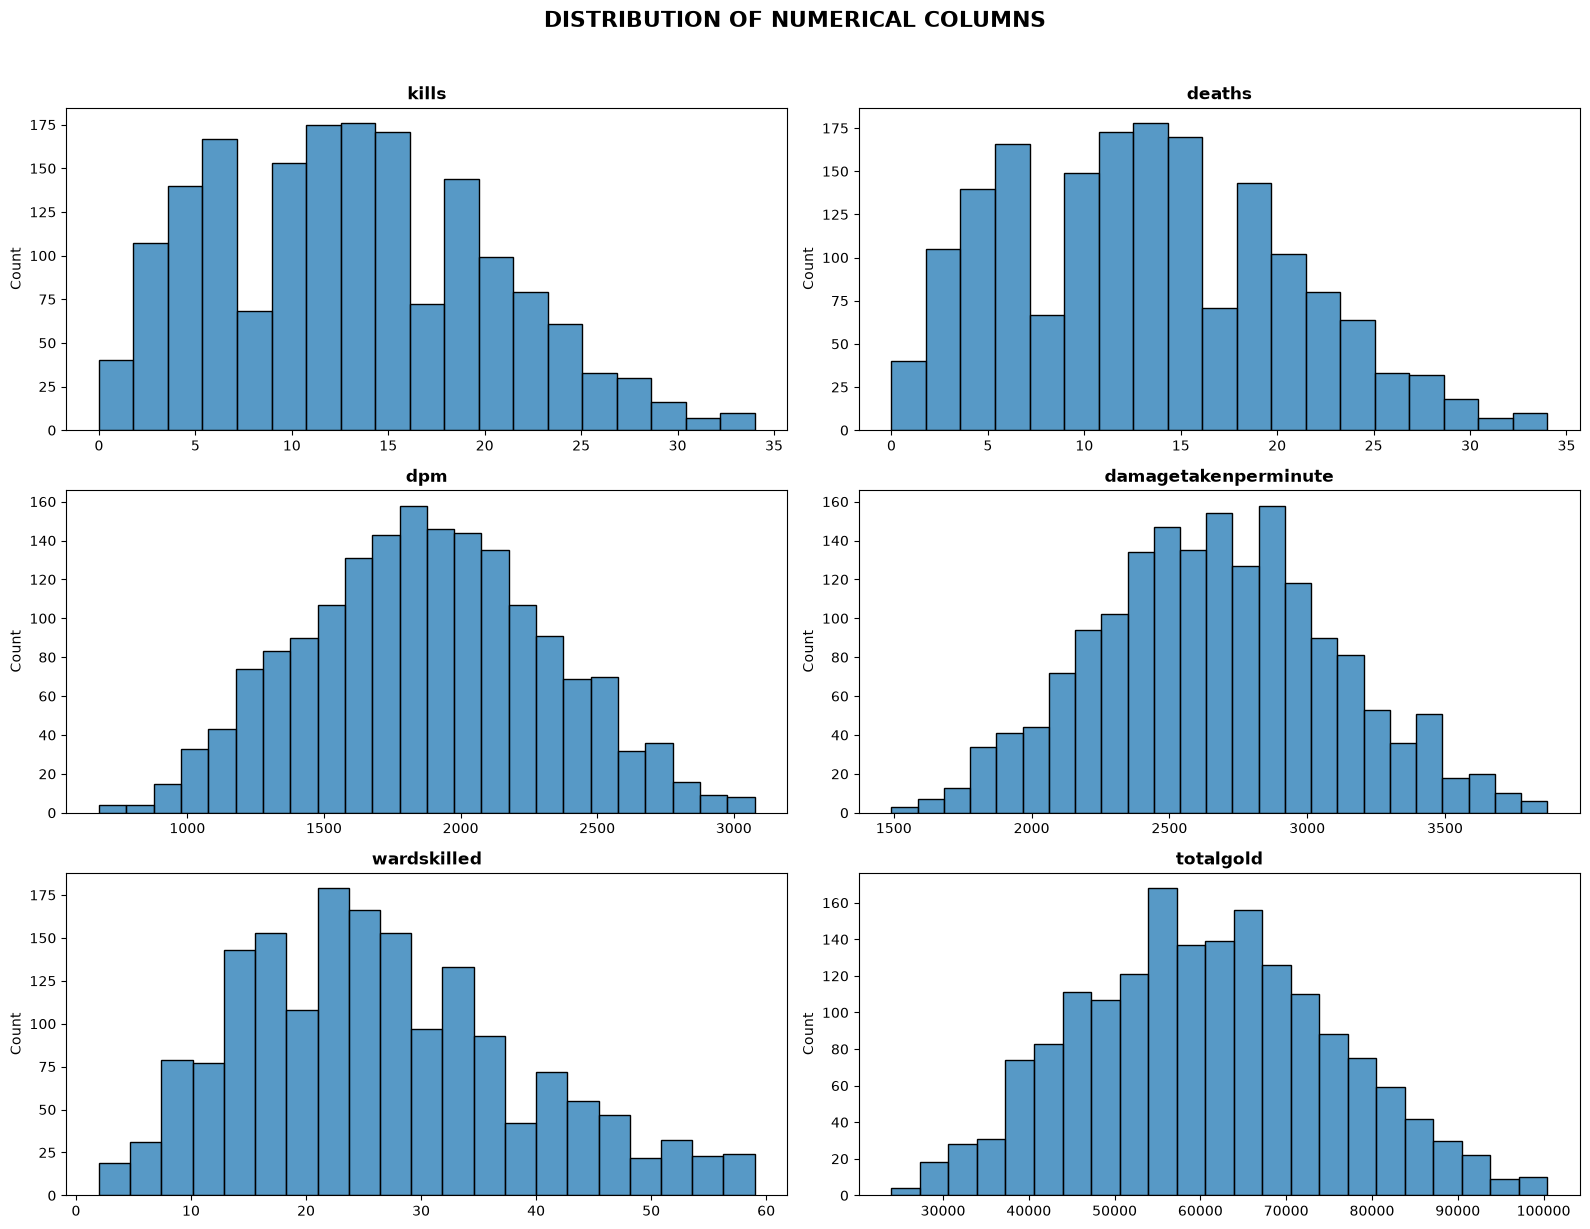

In [11]:
visualize_num_distribution(df, num_cols, nrows=3, ncols=2)

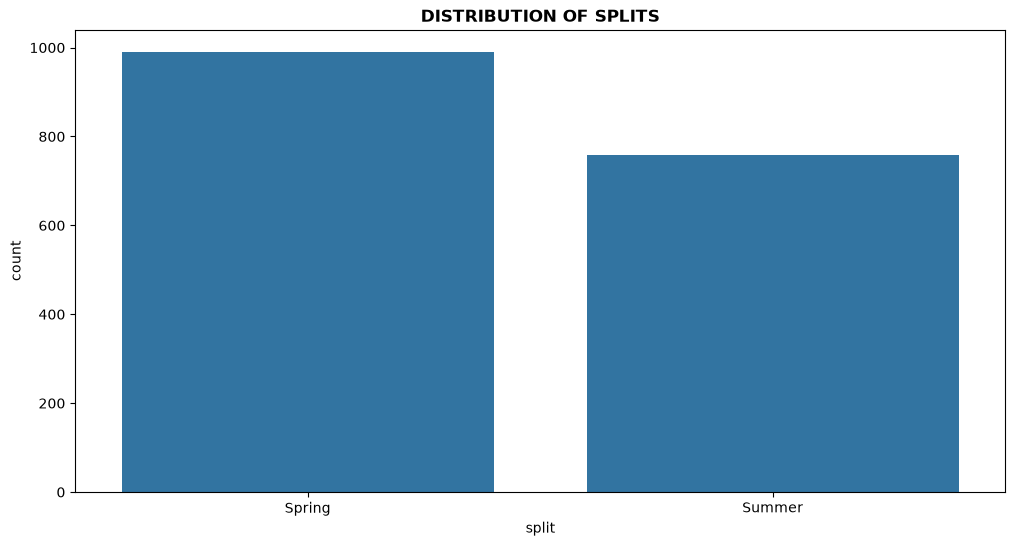

In [12]:
plt.figure(figsize=(12, 6))
sns.countplot(data=df, x='split')
plt.title('DISTRIBUTION OF SPLITS', fontsize=12, fontweight="bold")
plt.show()

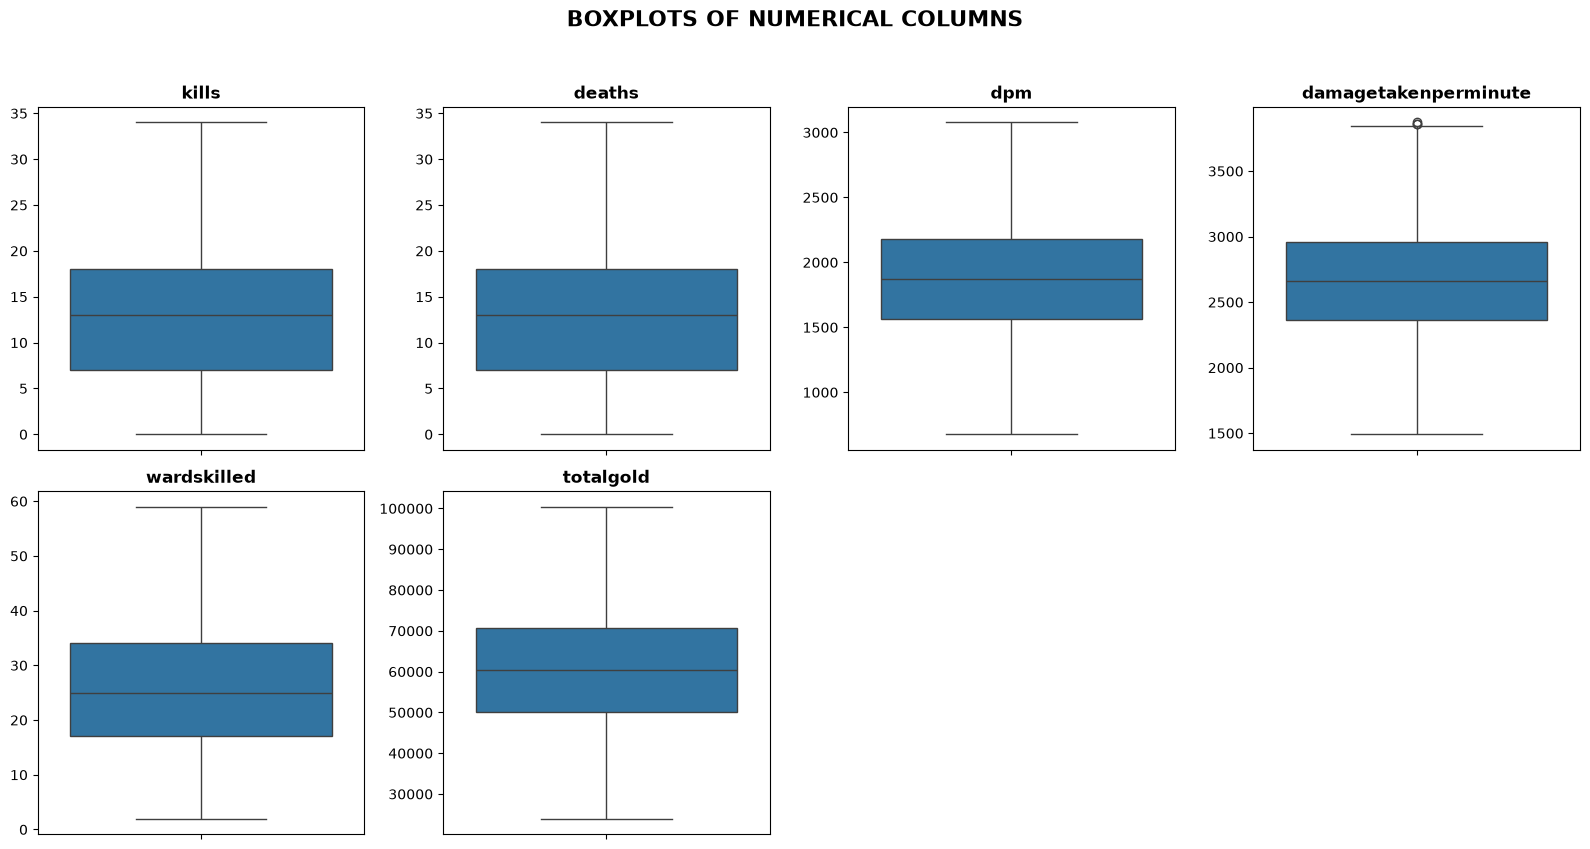

In [13]:
visualize_outliers(df, num_cols)

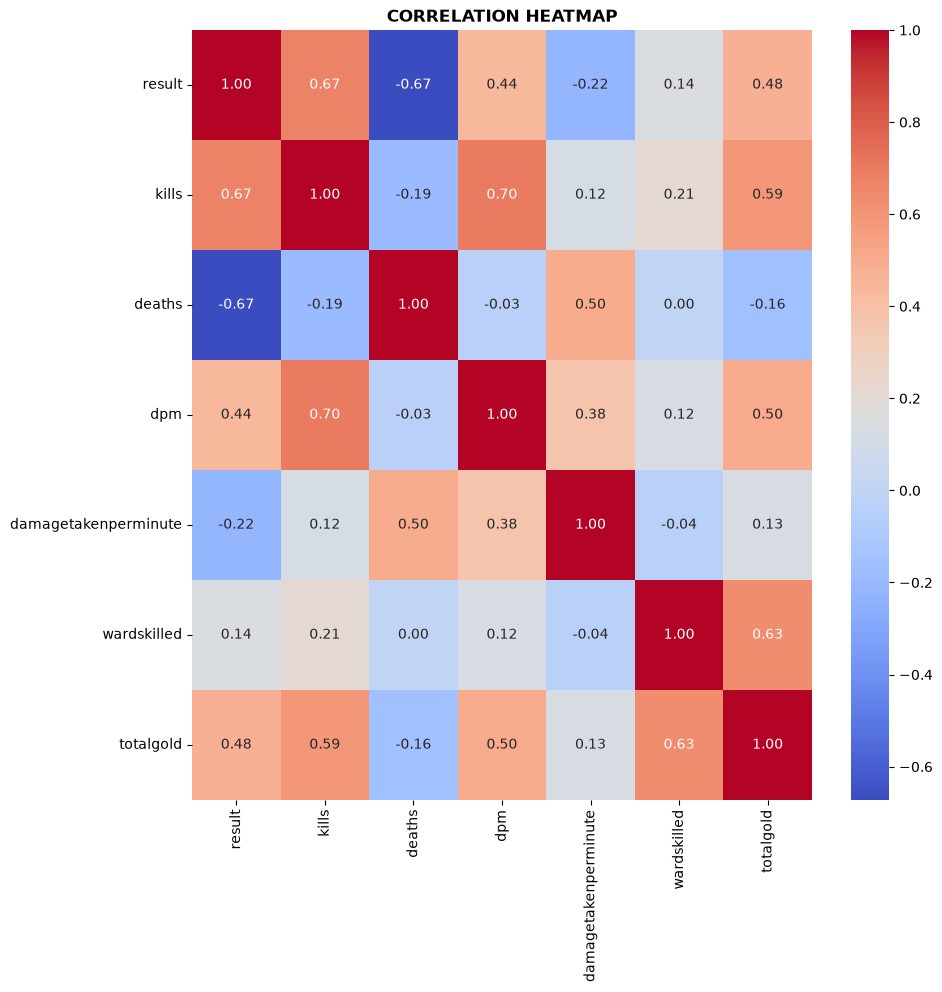

In [14]:
# Compute correlation matrix
co_mtx = df.corr(numeric_only=True)

# Plot correlation heatmap
plt.figure(figsize=(10, 10))
sns.heatmap(co_mtx, cmap='coolwarm', annot=True, fmt='.2f')
plt.title('CORRELATION HEATMAP', fontsize=12, fontweight="bold")
plt.show()